# Phase 1 + Phase 2 results

Analysis-only notebook: loads the checkpoints and histories produced by the training pipeline and presents them. No training happens here -- see `train_rainbow_minatar.ipynb` (Phase 0), `train_spr_minatar.ipynb` (Phase 1 seed-0 run), and `scripts/overnight_pipeline.py` (seed replication, CURL, iQRL, ablations, Atari smoke test) for how each result was produced.

**Environment/algorithm:** Rainbow DQN, MinAtar `breakout`, 100k env steps per run (50k for the Atari-100k smoke test), CPU-only. All error bars are 95% percentile-bootstrap confidence intervals of the interquartile mean across seeds (`diagnostics/bootstrap_ci.py`), not mean +/- std, following Agarwal et al. (2021).

## 1. Main comparison: baseline vs. SPR vs. CURL vs. iQRL (3 seeds each)

The project's core question, answered as far as this single-game, 100k-step, 3-seed budget allows. iQRL is adapted here as SPR's multi-step self-predictive structure with an FSQ quantization bottleneck in place of the momentum target network (`models/iqrl_head.py`), isolating quantization as its own anti-collapse mechanism rather than combining it with momentum.

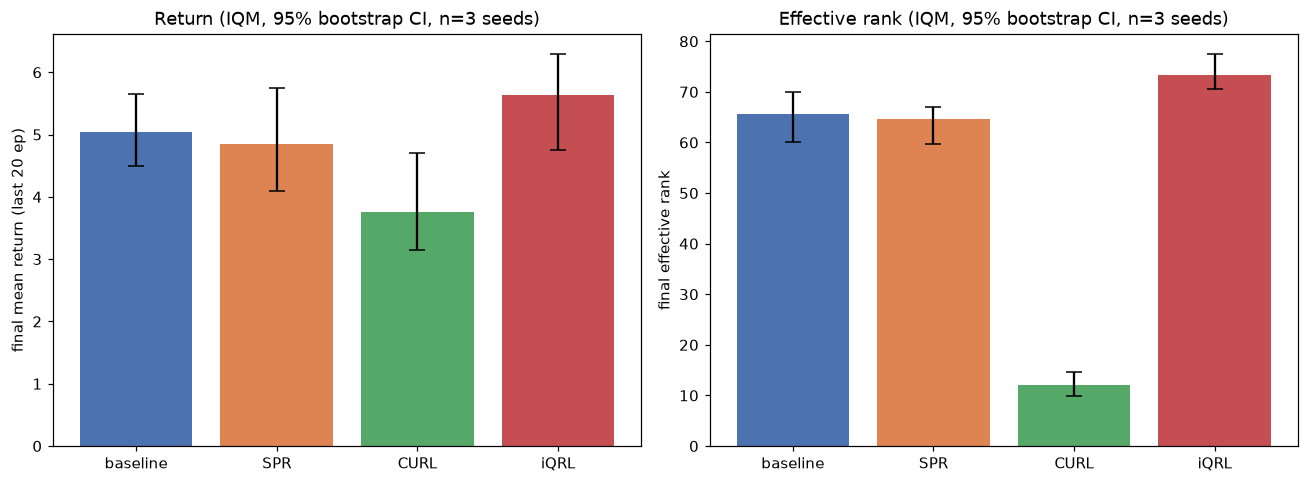

In [ ]:
# (plot embedded below)

### Full training curves (seed 0 of each)

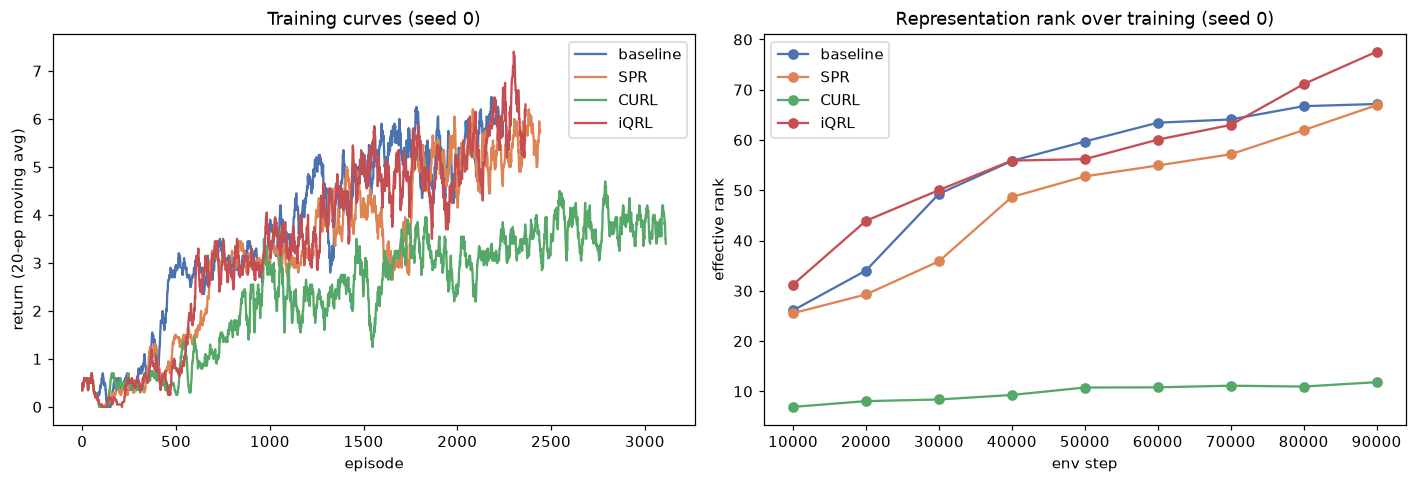

In [ ]:
# (plot embedded below)

## 2. Ablations: which part of SPR is doing the anti-collapse work? (2 seeds each)

`momentum_tau=0.0` removes EMA smoothing (target = online encoder, stop-gradient only); `aug_pad=0` removes the random-shift augmentation. Both use existing hyperparameters, no new code. **Preliminary** -- half the seed depth of the main comparison above, included as a mechanistic probe rather than a headline result.

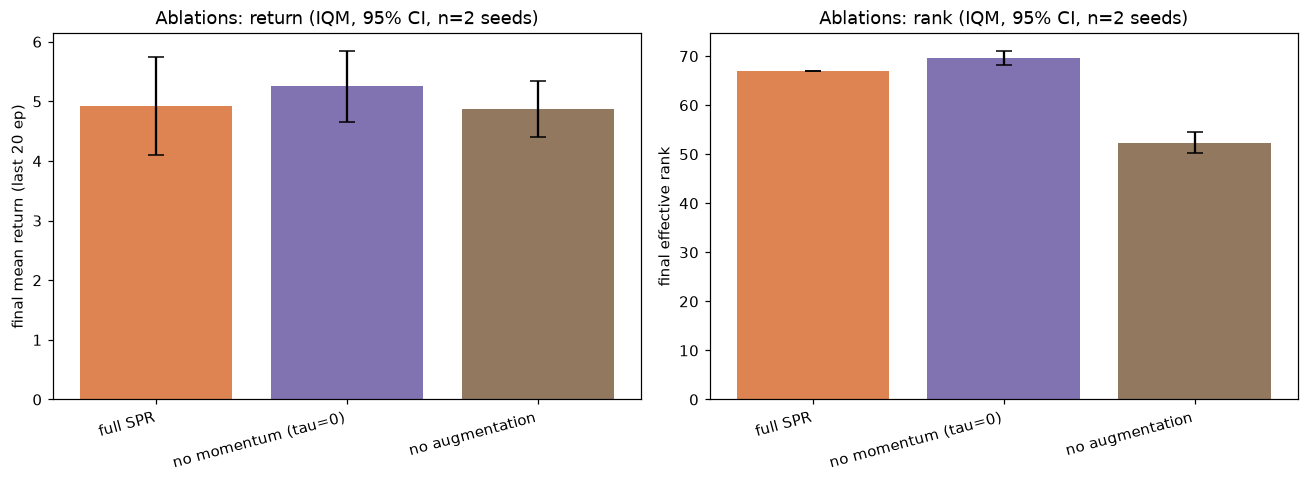

In [ ]:
# (plot embedded below)

## 3. Atari-100k infrastructure smoke test

Baseline Rainbow (no auxiliary loss) on real `ALE/Breakout-v5` with standard Atari-100k preprocessing, 50k steps. An earlier version of this run silently failed (zero reward for the entire run) due to a missing FIRE-on-reset step -- documented and fixed in `envs/atari_env.py`; this is the corrected result. Confirms the harder pixel-input pipeline learns correctly. SPR/CURL/iQRL have never been run on real Atari frames, and the full 26-game published-number reproduction remains out of scope (multi-day compute commitment).

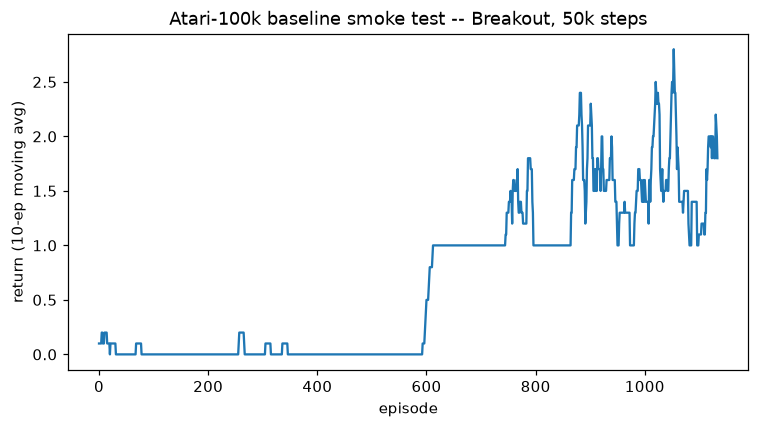

In [ ]:
# (plot embedded below)

## Summary

- baseline: return IQM=5.03 [4.50, 5.65], rank IQM=65.7 [60.1, 69.9] (seeds: [5.65, 4.95, 4.5])

- SPR: return IQM=4.85 [4.10, 5.75], rank IQM=64.5 [59.7, 67.1] (seeds: [5.75, 4.1, 4.7])

- CURL: return IQM=3.75 [3.15, 4.70], rank IQM=12.1 [9.8, 14.7] (seeds: [3.4, 3.15, 4.7])

- iQRL: return IQM=5.63 [4.75, 6.30], rank IQM=73.3 [70.6, 77.6] (seeds: [6.3, 5.85, 4.75])

- Ablation 'full SPR': return IQM=4.92 [4.10, 5.75], rank IQM=67.0 [66.9, 67.1] (seeds: [5.75, 4.1])

- Ablation 'no momentum (tau=0)': return IQM=5.25 [4.65, 5.85], rank IQM=69.7 [68.3, 71.1] (seeds: [4.65, 5.85])

- Ablation 'no augmentation': return IQM=4.88 [4.40, 5.35], rank IQM=52.4 [50.3, 54.5] (seeds: [4.4, 5.35])

- Atari-100k baseline smoke test: 1143 episodes over 50k steps, final mean return (last 10 ep) = 1.80.

## Limitations

- **Single game.** Everything above is MinAtar `breakout` only; no evidence yet that any of this generalizes to the other four MinAtar games, let alone real Atari.
- **Small, unequal seed counts.** 3 seeds for the main comparison, 2 for the ablations, 1 for nothing (this pass closed that gap, but 3 is still a small n -- the bootstrap CIs above are wide precisely because they're honest about that).
- **No hyperparameter search.** SPR/CURL/iQRL each use one reasonable configuration, not a tuned one; a method could look worse here than its ceiling.
- **Adapted, not reproduced.** None of the three methods' published numbers are reproduced here -- they were built to share this project's encoder/algorithm/environment instead, per its controlled-comparison design (see README). CURL's collapse and the ablation direction are specific to this adaptation and this setting, not necessarily the original methods.
- **Short budget.** 100k steps (50k for Atari) is small next to typical MinAtar training budgets in the literature; rankings could still be changing at the point training stopped.